In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeClassifier

# Load the same encoded data used in notebooks 10 and 11
df = pd.read_csv("D:/Mrunmayee/OneDrive/Desktop/student-performance-project/data/processed/student_encoded.csv")
print("Loaded dataset. Shape:", df.shape)

Loaded dataset. Shape: (395, 42)


The Random Forest (regression model):
Rebuild Model B's data split (Random Forest Regressor — no G1/G2)

In [2]:
X_b = df.drop(columns=['G1', 'G2', 'G3'])
y_reg = df['G3']

X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_b, y_reg, test_size=0.2, random_state=42
)

rf_b = RandomForestRegressor(n_estimators=100, random_state=42)
rf_b.fit(X_train_b, y_train_b)
print("Random Forest Regressor retrained.")

Random Forest Regressor retrained.


Rebuild Model B's data split (Decision Tree Classifier — no G1/G2)

In [3]:
df['pass_fail'] = (df['G3'] >= 10).astype(int)
X_clf_b = df.drop(columns=['G1', 'G2', 'G3', 'pass_fail'])
y_clf = df['pass_fail']

X_train_clf_b, X_test_clf_b, y_train_clf_b, y_test_clf_b = train_test_split(
    X_clf_b, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

dt_b = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_b.fit(X_train_clf_b, y_train_clf_b)
print("Decision Tree Classifier retrained.")

Decision Tree Classifier retrained.


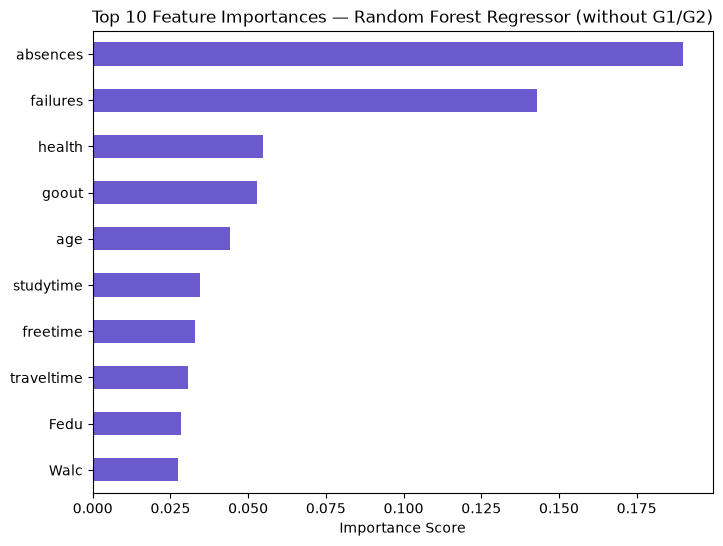

absences      0.189961
failures      0.143044
health        0.054743
goout         0.052796
age           0.044211
studytime     0.034359
freetime      0.033035
traveltime    0.030748
Fedu          0.028491
Walc          0.027564
dtype: float64


In [4]:
importances_rf = pd.Series(rf_b.feature_importances_, index=X_train_b.columns)
top_features_rf = importances_rf.sort_values(ascending=False).head(10)

plt.figure(figsize=(8,6))
top_features_rf.plot(kind='barh', color='slateblue')
plt.title("Top 10 Feature Importances — Random Forest Regressor (without G1/G2)")
plt.xlabel("Importance Score")
plt.gca().invert_yaxis()
plt.savefig("D:/Mrunmayee/OneDrive/Desktop/student-performance-project/outputs/figures/16_feature_importance_regression.png")
plt.show()

print(top_features_rf)

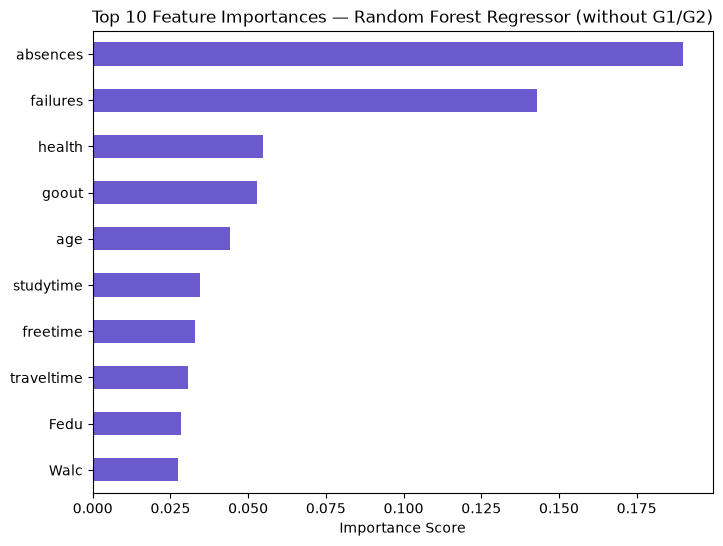

absences      0.189961
failures      0.143044
health        0.054743
goout         0.052796
age           0.044211
studytime     0.034359
freetime      0.033035
traveltime    0.030748
Fedu          0.028491
Walc          0.027564
dtype: float64


In [5]:
importances_rf = pd.Series(rf_b.feature_importances_, index=X_train_b.columns)
top_features_rf = importances_rf.sort_values(ascending=False).head(10)

plt.figure(figsize=(8,6))
top_features_rf.plot(kind='barh', color='slateblue')
plt.title("Top 10 Feature Importances — Random Forest Regressor (without G1/G2)")
plt.xlabel("Importance Score")
plt.gca().invert_yaxis()
plt.savefig("D:/Mrunmayee/OneDrive/Desktop/student-performance-project/outputs/figures/16_feature_importance_regression.png")
plt.show()

print(top_features_rf)

Decision Tree (classification model)

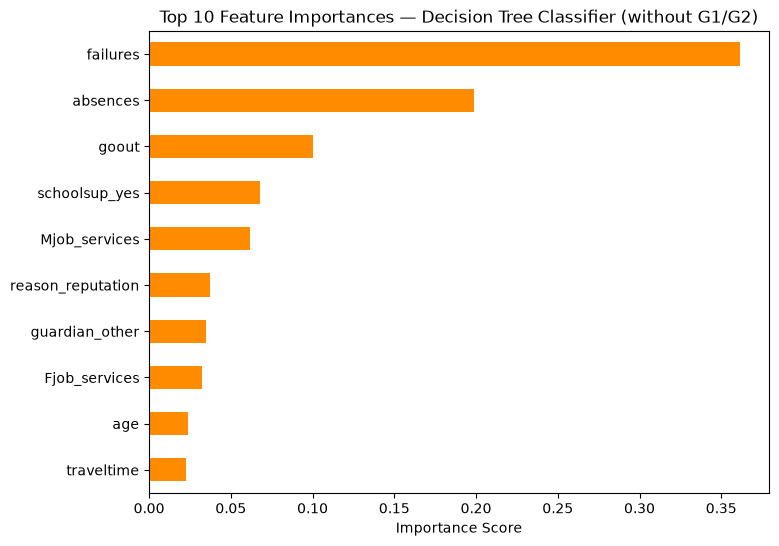

failures             0.361209
absences             0.198456
goout                0.100500
schoolsup_yes        0.067695
Mjob_services        0.061529
reason_reputation    0.037530
guardian_other       0.034561
Fjob_services        0.032252
age                  0.023900
traveltime           0.022554
dtype: float64


In [6]:
importances_dt = pd.Series(dt_b.feature_importances_, index=X_train_b.columns)
top_features_dt = importances_dt.sort_values(ascending=False).head(10)

plt.figure(figsize=(8,6))
top_features_dt.plot(kind='barh', color='darkorange')
plt.title("Top 10 Feature Importances — Decision Tree Classifier (without G1/G2)")
plt.xlabel("Importance Score")
plt.gca().invert_yaxis()
plt.savefig("D:/Mrunmayee/OneDrive/Desktop/student-performance-project/outputs/figures/17_feature_importance_classification.png")
plt.show()

print(top_features_dt)

"Failures, absences, and parental education consistently rank among the top predictors in both the regression and classification models. This indicates a strong statistical association between these factors and academic performance. However, this does not imply that, for example, absences directly cause lower grades — a student's absences may themselves be a symptom of other underlying issues (health, family circumstances, disengagement) that are the true drivers of lower performance. Feature importance reflects predictive usefulness, not causal mechanism.""Failures and absences dominate the Decision Tree's feature importance, together accounting for over 55% of the model's total decision-making weight. This aligns with intuition: students who have already failed a class or who miss school frequently are naturally more likely to underperform. Interestingly, 'going out with friends' (goout) ranks third, ahead of most demographic factors, suggesting social/lifestyle behavior carries more predictive weight than parental background in this dataset. School support (schoolsup_yes) and mother's job type (Mjob_services) also contribute meaningfully. Notably, parental education (Medu, Fedu) does not appear in the top 10 — despite showing up in earlier correlation analysis — indicating that while parental education has some linear association with G3, it is not among the most decisive factors when the Decision Tree considers combinations of variables. This distinction itself is worth noting in the report: correlation and feature importance can disagree, because they measure different things (linear relationship vs. decision-splitting usefulness)."